In [1]:
import sys
sys.path.append('/home/nathan/thermo_flux')

import pandas as pd
import os
# Add the parent directory to sys.path
sys.path.append(os.path.abspath('../3_src/'))
# Now import Model from freeflux
from freeflux.src.freeflux import Model

from HELPER_FREEFLUX_NF import io as nf_io
import numpy as np
from HELPER_FREEFLUX_NF import fit_netfluxes as nf_fit
from HELPER_FREEFLUX_NF import c13problem_class as c13
from analysis import an_func as an_func
import analysis.io_func as io_func
import seaborn as sns
import matplotlib.pyplot as plt

from analysis import config_13c as config

In [29]:
condition='WT' 
model=config.model
net_flux_df=config.net_flux_df(condition)
obj_vals=config.obj_vals(condition)
n_perc=5
# accepted_samples=obj_vals[obj_vals<=np.percentile(obj_vals,n_perc)].index

bootstrap_samples=pd.read_csv(f'{config.FREEFLUXRUN_FOLDER}/bootstrap_chosensamples{condition}.csv',index_col=0).values.T[0]
ISO_OUTPUT_FOLDER=config.RESULTS_FOLDER+str('d_predict_isotopes/')

shencond='Climited' if condition=='TM6' else 'CENPK'

In [3]:
# Import general configs:
palette ,cmap,cfg =io_func.import_plotconfigs(cpalette=True)
colors=[palette[0],palette[1],palette[4]]
sns.set_palette(colors)

# tracer used : 1,2 - GLC , 50%

## sim  extended data from SHEN with WT strain with
for each net flux sample we have a fitted optu -> fwd and bckwd fluxes.

for these, we have the simulated MDVs. 

We can compare the simulated MDVs of other intracellular metabolites for the different opt u that we get.

Later, we will also compare them to the value measured in SHEN

In [4]:
sample_n0=44
c13_problem=c13.c13_problem(condition,'1-13C',sample_n0,config.MODEL_FILE,config.flux_file(condition),config.INPUT_FOLDER,os.getcwd(),'sim_SHEN',df_ex_flux='a',force_flux=False,scale=1e-3,
                           extended_data=True,eq_constr=True)


In [5]:
self=c13_problem
fit=None
fit = self.modelA.fitter('ss')
fit.set_labeling_strategy('glcDe', ['000011'],[0.5],[0.99])
# fit.set_labeling_strategy('glcDe', ['111111'],[0.5],[0.99]) ## for U
self.n_jobs=4


self.df_label_data=self._get_label_df()
nf_fit.helper_set_MDV(fit,nf_fit.data_to_MDV_mix_func(self.df_label_data))
# time=datetime.now().strftime("%d/%m/%Y %H:%M:%S")
# print(f'>>>> preparing at : {time}')
nf_fit.helper_prepare(fit,n_jobs=self.n_jobs) #prepare cut in 2 parts for later optimization whselfen running on a large number of samples

##after this is for the objective to regress to sample fluxes
dict_fluxes=nf_io.load_sample_fromdf(self.sample_no,self.net_flux_df)

vnet=[dict_fluxes[key] if self.modelA.reactions_info[key].reversible else abs(dict_fluxes[key]) for key in fit.model.reactions if key in dict_fluxes.keys()]
fit.vnet=vnet
##measured fluxes part : 
print(f'{self.fit_fluxes} fitfluxes')
if self.fit_fluxes==True:
    df_ex_flux_cond=self.df_ex_flux.loc[self.condition]
    nf_fit.fit_set_measfluxes(fit,df_ex_flux_cond)

#continue prepare
if self.flux_bounds == True : #case for false not implemented here
    nf_fit.helper_set_flux_bounds(fit,self.net_flux_df,self.sample_no,1e-3,reset=False)
elif self.flux_bounds == 'VA':
    nf_fit.set_VA_bounds(fit,self.modelA,self.condition) #va bounds file is hardcoded in fit_netfluxes.py
    
nf_fit.helper_prep_part2(fit,bound=self.flux_bounds)

False fitfluxes
bound were set if True otherwise default True


In [6]:
c13_problem.fitA=fit

In [8]:
# c13_problem.labeling_strategy='U-13C'
# c13_problem._set_fit()
c13_problem.force_flux=False
c13_problem.optModelA=c13_problem._build_optmodel()

### load samples folder

In [9]:
#replace N with one from cluster
# c13_problem.optModelA.N=pd.read_csv(f'{BASE_FOLDER}/4_results/c_FREEFLUX_run/nullspace_newnumpy.csv',header=None,sep=' ').values
c13_problem.N=pd.read_csv(f'{config.FREEFLUXRUN_FOLDER}/nullspace_hpc.csv',index_col=0).values

###fluxes df
cmodel_df=pd.read_csv(config.flux_file(condition),index_col=0)
cmodel_df.columns=[int(i) for i in cmodel_df.columns]

In [ ]:
# ## best sample ##load u and run f(U ): N@u = vtot
# sample_n0=obj_vals.sort_values().index[0]
# filename=f'optu_{condition}_combined_sample{sample_n0}.csv'
# optu=an_func._load_u_fromfile(f'{config.FREEFLUXRUN_FOLDER}{condition}/{filename}')
# c13_problem.optModelA.model.total_fluxes[:407]=c13_problem.N@optu
# # c13_problem.optModelA.f(optu)c

FileNotFoundError: [Errno 2] No such file or directory: '/home/nathan/PhD/04.Computational/202601_13C//4_results//c_freeflux_run/WT/optu_WT_combined_sample133.csv'

load input data and format

In [14]:
#### load mets that we want to look at 
# values column are a list with ' ' as separator, make an actual list of floats
raw_data=pd.read_excel(f'{config.DATA_FOLDER}/a_raw_data/13C_isotopomerdata_Shen2024/data_expmt2_{shencond}.xlsx',sheet_name='manualprocessed_data')
processed_df=raw_data.copy()
processed_df['values'] = raw_data['values'].apply(lambda x: [float(i) for i in str(x).split()])
processed_df['n_fragment']=processed_df['ms_id'].str.split('-').str[-1].str.split(',').apply(len)
processed_df['ms_id']=[i.split('-')[0] for i in processed_df['ms_id']]
processed_df.set_index('ms_id',inplace=True)

# processed_df.index=[str(i)+'_'+str([j for j in range(1,processed_df["n_fragment"].loc[i]+1)]).replace('[','').replace(']','').replace(',','') for i in processed_df.index]
##for expmt 2 i didnt remove the __ before the L . remove it here
processed_df.index=processed_df.index.str.replace('__L','L')
processed_df.index=processed_df.apply(
    lambda row: f"{row.name}_{''.join(str(i) for i in range(1, row['n_fragment'] + 1))}",
    axis=1
)
# processed_df

In [15]:
#from this list we want to get isotopomer fractions of met if it is only in c, and otherwise make up c AND m metabolite
##so it is the list of cytosolic isotope fractions and compartmental (c and m)isotope fractions
met_meas_tup=[i if 'd2' not in i
              else (f"{i.split('_')[0]}c_{i.split('_')[-1]}", f"{i.split('_')[0]}m_{i.split('_')[-1]}")
              for i in processed_df.index]
isotopef_list_data = [item for entry in met_meas_tup for item in (entry if isinstance(entry, tuple) else [entry])]
# isotopef_list_data


In [16]:
#### example step that we will take on all samples : 
# sim mdvs of all EMU
simMDVs_all=c13_problem.optModelA.calculator._calculate_MDVs()
#tthen keep only emu that correspond to measured mets
simMDVs={key:val for key,val in simMDVs_all.items()  if key in isotopef_list_data}


## now get the dict for all samples (as a df)

In [36]:
intramet_MDVsall={}
for sample_n0 in range(1000):
    filename=f'optu_{condition}_combined_sample{sample_n0}.csv'
    try : 
        optu=an_func._load_u_fromfile(f'{config.FREEFLUXRUN_FOLDER}{condition}_fit2/{filename}')
        # c13_problem.optModelA.f(optu)
        c13_problem.optModelA.model.total_fluxes[:407]=c13_problem.N@optu
        simMDVs=c13_problem.optModelA.calculator._calculate_MDVs()
        intramet_MDVsall[sample_n0]={key:val for key,val in simMDVs.items()  if key in isotopef_list_data}
    except Exception as e : 
        print(e)
        pass
    if sample_n0%100==0:
        df_intrametsMDVsall=pd.DataFrame(intramet_MDVsall)
        # df_intrametsMDVsall.to_csv(f'{ISO_OUTPUT_FOLDER}/{condition}_SHEN_intrametsMDVsall_12_GLC.csv')


[Errno 2] No such file or directory: '/home/nathan/PhD/04.Computational/202601_13C//4_results//c_freeflux_run/WT_fit2/optu_WT_combined_sample143.csv'
[Errno 2] No such file or directory: '/home/nathan/PhD/04.Computational/202601_13C//4_results//c_freeflux_run/WT_fit2/optu_WT_combined_sample460.csv'
[Errno 2] No such file or directory: '/home/nathan/PhD/04.Computational/202601_13C//4_results//c_freeflux_run/WT_fit2/optu_WT_combined_sample900.csv'
[Errno 2] No such file or directory: '/home/nathan/PhD/04.Computational/202601_13C//4_results//c_freeflux_run/WT_fit2/optu_WT_combined_sample936.csv'


In [ ]:
# note that best comparison is with WT because it is same strain
# df_intrametsMDVsall=pd.DataFrame(intramet_MDVsall)
# df_intrametsMDVsall.to_csv(f'{ISO_OUTPUT_FOLDER}/{condition}_SHEN_intrametsMDVsall_12_GLC.csv')

In [17]:
### if read from file
def parse_array_string(s):
    s = s.strip()
    if s.startswith('[') and s.endswith(']'):
        s = s[1:-1].strip()
        if s:  # Avoid empty arrays
            return np.array([float(x) for x in s.split()])
    return []
df_intrametsMDVsall=pd.read_csv(f'{ISO_OUTPUT_FOLDER}/{condition}_SHEN_intrametsMDVsall_12_GLC.csv',index_col=0)#,converters={col: ast.literal_eval for col in range(1, 1000)})
df_intrametsMDVsall=df_intrametsMDVsall.applymap(parse_array_string)
df_intrametsMDVsall.columns = [int(col) for col in df_intrametsMDVsall.columns]

we can also differentiate the diluted mets (present in both compartments) or only cytosolic mets

In [18]:
cyt_mets=[i for i in processed_df.index if 'd2' not in i ]
# shendata=processed_df.loc[df_intrametMDVs.index.intersection(cyt_mets)]
cyt_mets

['argLc_123456',
 'aspLc_1234',
 'fdpc_123456',
 'g6pc_123456',
 'glyc3pc_123',
 'ileLc_123456',
 'leuLc_123456',
 'lysLc_123456',
 'pepc_123',
 'pheLc_123456789',
 'proLc_12345',
 'r5pc_12345',
 's7pc_1234567',
 'serLc_123',
 'trpLc_1234567891011',
 'tyrLc_123456789',
 'valLc_12345']

In [19]:
intramet_cyt=df_intrametsMDVsall.loc[df_intrametsMDVsall.index.intersection(cyt_mets)]
## for each cell, compute residual with shendata[valuess]
# Apply element-wise subtraction row-wise
def subtract_base(row,base):
    base_list = base.loc[row.name,'values']
    return row.apply(lambda x: sum([(a - b)**2/0.1**2 for a, b in zip(x, base_list)]))

## now for remaining metabolites

we have to use compartmentalized concentrations. so we get our ranges, and we will compute ranges for xi .. with cvxpy ? 


In [71]:
# ## load conc ranges
# fold=f'{BASE_FOLDER}/4_results/d_lncVA/{condition}/'
# df_lnconc_b=np.round(pd.read_csv(f'{fold}/{condition}_indivfluxbounds_lncbounds.csv',index_col=(0,1)),4)#.loc[accepted_samples]
# # df_lnconc_b

In [20]:
mixed_mets=[i for i in df_intrametsMDVsall.index if i not in cyt_mets]
# shendata_mixedmet
intramet_mixed_alls=df_intrametsMDVsall.loc[mixed_mets]

we could use the center of the previous ranges, but so narrow that we just use cyt values here ?

In [ ]:
### if we use equal conc c and m 
# all_data=processed_df.loc[df_intrametMDVs.index]
# processed_df
Cc=1
Cm=1
#i have to create a new df where d1 is a met with values being just c values
df_allsamp_all_mdv_eqconc=pd.DataFrame(columns=df_intrametsMDVsall.columns)
for met in [m for m in mixed_mets if 'm_' in m]:
    met_d1=met.split('_')[0][:-1]+'_d2_'+met.split('_')[1]
    metc=met.split('_')[0][:-1]+'c_'+met.split('_')[1]
    # print(met)
    df_allsamp_all_mdv_eqconc.loc[met_d1]=(df_intrametsMDVsall.loc[met]*0.05*Cm + df_intrametsMDVsall.loc[metc]*0.95*Cc)/(0.05*Cm+0.95*Cc)

for met in intramet_cyt.index:
    df_allsamp_all_mdv_eqconc.loc[met]=intramet_cyt.loc[met].values
# df_all_mdv


because here we kept ranges of allowed isotope fractions (as list of tuples), we cant just substract the base value to a single value for d1 met

2 cases : cyt met or mixed met 
- cyt met is easy
- mixed met -> 2 stpes
    - if data is inside range , best case is res=0, worst is max(ub-data,lb -data)
    - if outside, best case is min(ub-data,lb -data), worst is max(ub-data,lb -data)

In [22]:
all_data=processed_df.loc[df_allsamp_all_mdv_eqconc.index]

df_sub_equalconc=df_allsamp_all_mdv_eqconc.apply(lambda row : subtract_base(row,all_data), axis=1)
df_sub_equalconc.columns=[int(i) for i in df_sub_equalconc.columns]

plot measured vs simulated across all mets 

for each met, sample : compare the two arrays one value by one value (df_allsamp.loc[met,sample], all_data.loc[met,value])
each comparison makes a point in a scatter plot

In [127]:
plt.rcParams['text.usetex'] = False

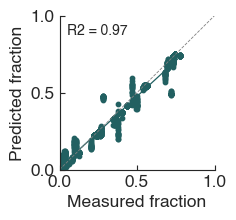

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

x_top = []
y_top = []

for met in all_data.index:
    measured = np.asarray(all_data.loc[met, "values"])

    for sample in bootstrap_samples:
        simulated = np.asarray(df_allsamp_all_mdv_eqconc.loc[met, sample])

        if np.any((simulated < 0) | (simulated > 1)):
            continue

        x_top.extend(measured)
        y_top.extend(simulated)

x_top = np.asarray(x_top)
y_top = np.asarray(y_top)

r, _ = pearsonr(x_top, y_top)
r2 = r**2

fig, ax = plt.subplots(1, 1, figsize=(2, 2))
io_func.scale_rcparams(fig)

sns.regplot(x=x_top, y=y_top, ax=ax, scatter_kws={'s': 10, 'alpha': 1}, ci=None)

ax.plot([0, 1], [0, 1], transform=ax.transAxes, **cfg['settings_diagonal'])

ax.text(0.05, 0.95, rf"R2 = {r2:.2f}", transform=ax.transAxes,
        ha='left', va='top',fontsize=10)

ax.set_xlabel("Measured fraction")
ax.set_ylabel("Predicted fraction")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_yticks([0, 0.5, 1])

# plt.savefig(f'{config.GEN_PLOTS_FOLDER}/fig7a_bootstrap_regplot_simvsmeas_12GLCSHEN.png',bbox_inches='tight',dpi=300)
# plt.savefig(f'{config.GEN_PLOTS_FOLDER}/fig7a_bootstrap_regplot_simvsmeas_12GLCSHEN.svg',bbox_inches='tight',dpi=300)

In [45]:
config.GEN_PLOTS_FOLDER

'/home/nathan/PhD/04.Computational/202601_13C//2_notebooks/Figures/'

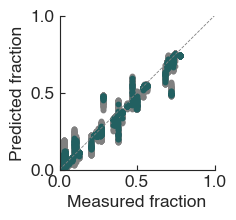

In [32]:
import numpy as np
import matplotlib.pyplot as plt

x = []  # measured
y_all = []  # simulated
x_top=[]
y_top=[] #top5

for met in all_data.index:
    measured = np.asarray(all_data.loc[met, "values"])

    for sample in df_allsamp_all_mdv_eqconc.columns:
        simulated = np.asarray(df_allsamp_all_mdv_eqconc.loc[met, sample])
                # Skip invalid MDVs
        if np.any((simulated < 0) | (simulated > 1)):
            continue
        

        # one point per isotopomer
        x.extend(measured)  
        y_all.extend(simulated)

        if sample in bootstrap_samples:
            x_top.extend(measured)
            y_top.extend(simulated)


x = np.asarray(x)
x_top = np.asarray(x_top)
y_all = np.asarray(y_all)
y_top = np.asarray(y_top)

fig,ax=plt.subplots(1,1,figsize=(2,2))
io_func.scale_rcparams(fig)
# idx = np.random.choice(len(x), 50000, replace=False)
# ax.scatter(x[idx], y_all[idx],  s=10,alpha=1,color='grey',rasterized=True)
ax.scatter(x, y_all, s=10, alpha=1,color='grey',rasterized=True)
ax.scatter(x_top, y_top, s=10)

ax.plot([0, 1], [0, 1], transform=ax.transAxes,**cfg['settings_diagonal'])

ax.set_xlabel("Measured fraction")
ax.set_ylabel("Predicted fraction")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_yticks([0, 0.5, 1])
##save fig

# plt.savefig(f'{config.GEN_PLOTS_FOLDER}/fig7a_scatter_simvsmeas_12GLCSHEN.png',bbox_inches='tight',dpi=300)
# plt.savefig(f'{config.GEN_PLOTS_FOLDER}/fig7a_scatter_simvsmeas_12GLCSHEN.svg',bbox_inches='tight',dpi=300)

we can check individual isotopomers for the fit of their fractions

In [76]:
## add individual labeling bar plot in the boxen plot above.
met='glyc3pc'
def make_dfplot(met,df):
    metname=[i for i in df.index if met in i][0]
    mdvs_allsamp_met=df.loc[metname]
    df_exp=pd.DataFrame(mdvs_allsamp_met.explode())
    labels=metname.split('_')[-1]
    label_range=[0]+[int(i) for i in labels]
    print(label_range)
    df_exp['n_labels']=label_range* ((len(df_exp) + len(label_range)-1) // len(label_range))
    dfplot = df_exp.groupby('n_labels')[metname].agg(['mean', 'std']).reset_index()
    dfplot['type']='simulated'
    tmp_expd=pd.DataFrame(pd.Series(all_data.loc[metname,'values']).explode()).rename(columns={0:'mean'})
    tmp_expd['std']=0.01
    tmp_expd['n_labels']=label_range
    tmp_expd['type']='measured'
    dfplot=pd.concat([dfplot,tmp_expd])
    return dfplot
# dfplot

[0, 1, 2, 3]


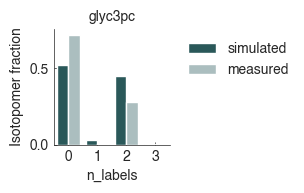

In [ ]:
fig,ax=plt.subplots(1,1,figsize=(1.5,1.5))
io_func.scale_rcparams(fig,scalingf=0.25)
met='glyc3pc' 
#all samples
# dfplot=make_dfplot(met,df_allsamp_all_mdv_eqconc)
# sns.barplot(ax=ax[0],data=dfplot, x='n_labels', y='mean',hue='type')
#accepted
dfplot=make_dfplot(met,df_allsamp_all_mdv_eqconc.loc[:,bootstrap_samples[1:2]])
sns.barplot(ax=ax,data=dfplot, x='n_labels', y='mean',hue='type')
#remove legend on both axes
# for axi in ax:
#     axi.get_legend().remove()



ax.legend(frameon=False,bbox_to_anchor=(1.05, 1), loc='upper left',fontsize=10)
ax.set_ylabel('Isotopomer fraction')
ax.set_title(met,fontsize=10,loc='center')
# #change font size of ticks
for item in ([ax.title, ax.xaxis.label, ax.yaxis.label] +
             ax.get_xticklabels() + ax.get_yticklabels()):
    item.set_fontsize(10)
#save## done with g6pc and fdpc and s7pc
# plt.savefig(f'{config.GEN_PLOTS_FOLDER}/fig6e_bars_residuals_{met}_12GLC.png',bbox_inches='tight',dpi=600)
# plt.savefig(f'{config.GEN_PLOTS_FOLDER}/fig6e_bars_residuals_{met}_12GLC.svg',bbox_inches='tight',dpi=600)